# Task 1 — Prove why we visualize

This notebook uses the Datasaurus dataset. The main point is that very different shapes can share almost identical summary statistics.

## Goal
1. Compute summary statistics for each dataset.
2. Plot all 13 datasets as a grid of scatterplots.
3. Explain why the table alone can be misleading.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

path = Path('data') / 'datasaurus.csv'
df = pd.read_csv(path)
df.head()


,dataset,x,y
0,dino,55.3846,97.1795
1,dino,51.5385,96.0256
2,dino,46.1538,94.4872
3,dino,42.8205,91.4103
4,dino,40.7692,88.3333


## 1) Summary table per dataset
The table below shows the mean, standard deviation, and correlation for each of the 13 datasets.

In [3]:
summary = df.groupby('dataset').apply(lambda g: pd.Series({
    'x_mean': g['x'].mean(),
    'y_mean': g['y'].mean(),
    'x_sd': g['x'].std(ddof=1),
    'y_sd': g['y'].std(ddof=1),
    'corr': g['x'].corr(g['y'])
})).reset_index()
summary.sort_values('dataset')


/var/folders/b7/n66x67qj3_57sghtm4d552j00000gn/T/ipykernel_90521/3080859779.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = df.groupby('dataset').apply(lambda g: pd.Series({


,dataset,x_mean,y_mean,x_sd,y_sd,corr
0,away,54.266100,47.834721,16.769825,26.939743,-0.064128
1,bullseye,54.268730,47.830823,16.769239,26.935727,-0.068586
2,circle,54.267320,47.837717,16.760013,26.930036,-0.068343
3,dino,54.263273,47.832253,16.765142,26.935403,-0.064472
4,dots,54.260303,47.839829,16.767735,26.930192,-0.060341
5,h_lines,54.261442,47.830252,16.765898,26.939876,-0.061715
6,high_lines,54.268805,47.835450,16.766704,26.939998,-0.068504
7,slant_down,54.267849,47.835896,16.766759,26.936105,-0.068980
8,slant_up,54.265882,47.831496,16.768853,26.938608,-0.068609
9,star,54.267341,47.839545,16.768959,26.930275,-0.062961


## 2) Plot all 13 datasets
A grid of scatterplots reveals the real structure. The summary table hides it.

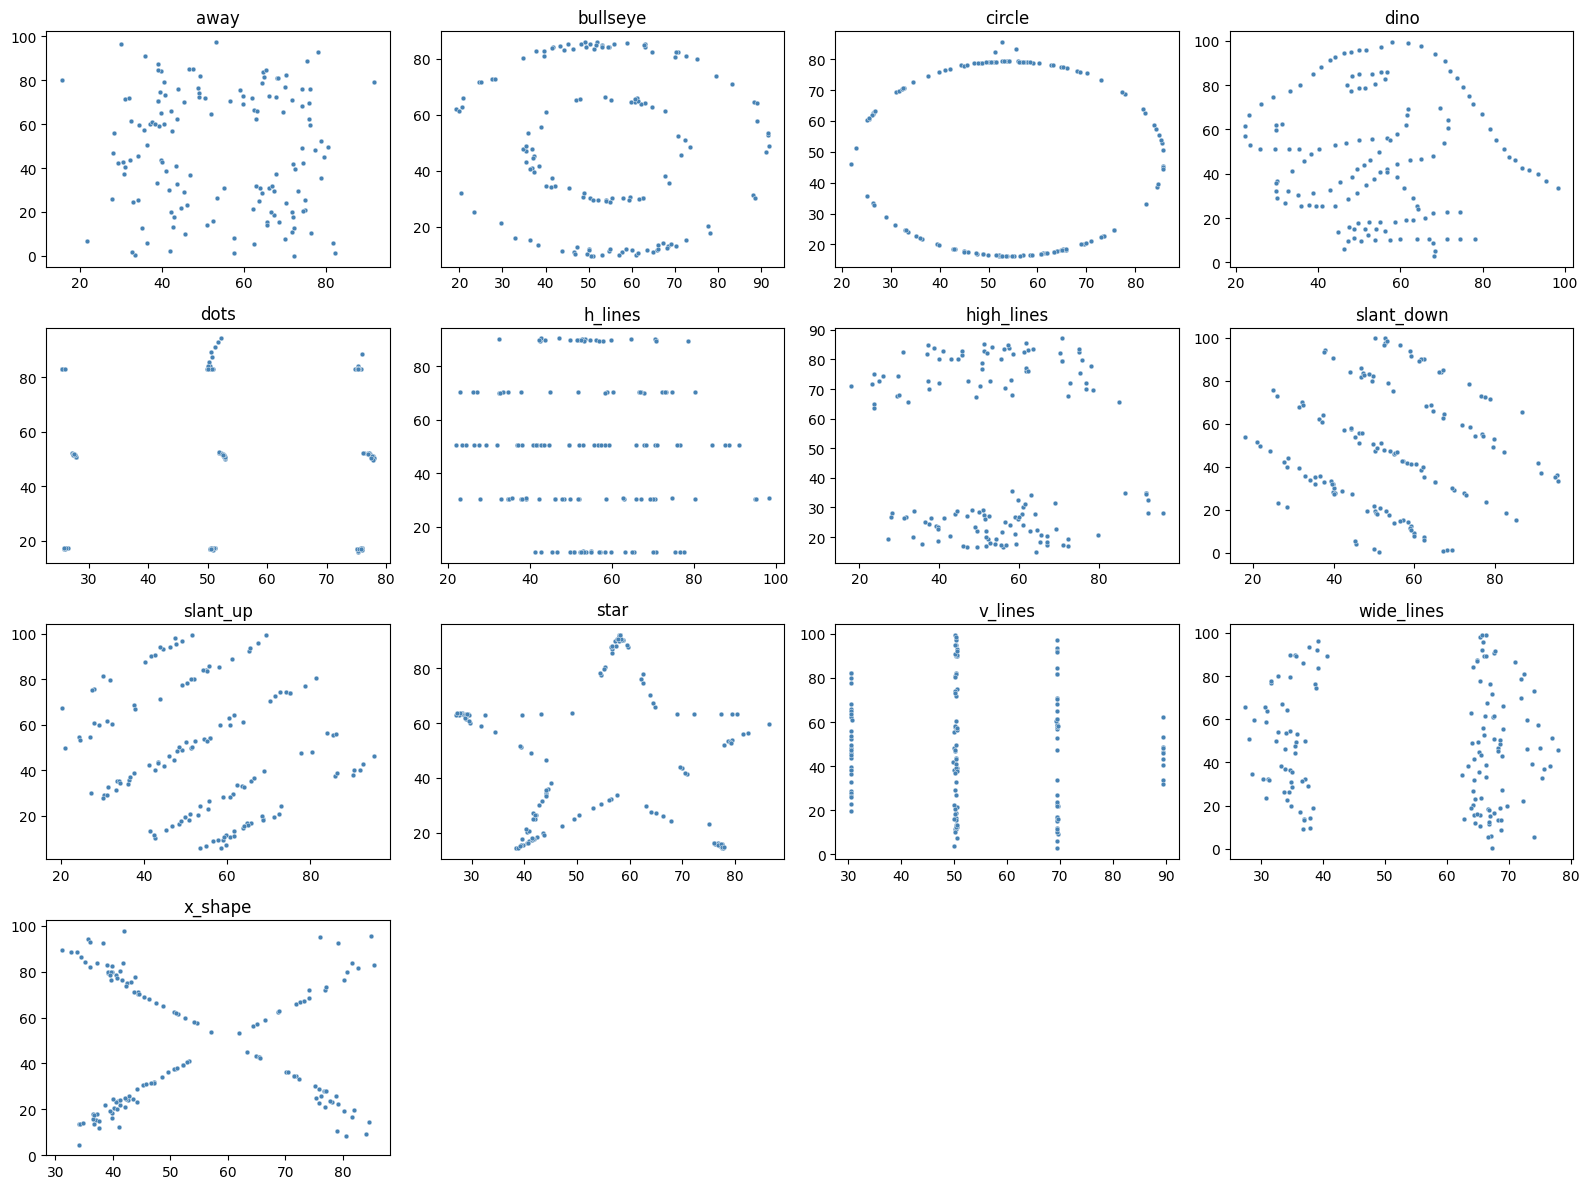

In [4]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12), sharex=False, sharey=False)
axes = axes.flatten()

for ax, (name, group) in zip(axes, df.groupby('dataset')):
    sns.scatterplot(data=group, x='x', y='y', ax=ax, color='steelblue', s=12)
    ax.set_title(name)
    ax.set_xlabel('')
    ax.set_ylabel('')

# hide any unused panels
for ax in axes[len(df['dataset'].unique()):]:
    ax.axis('off')

fig.tight_layout()
plt.show()


### Interpretation
The means, standard deviations, and correlation are nearly the same across datasets, but the plots show completely different shapes. This is exactly why we visualize: summary statistics compress the signal and can hide the story in the data.